In [1]:

#  IMPORT LIBRARIES

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [2]:
#dataset

BASE_DIR = "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)"

TRAIN_DIR = os.path.join(BASE_DIR, "train")
VALID_DIR = os.path.join(BASE_DIR, "valid")

In [3]:
#  NUMBER OF CLASSES


classes = sorted(os.listdir(TRAIN_DIR))

print(f"Total Classes : {len(classes)}")

for i, cls in enumerate(classes):
    print(i, cls)

Total Classes : 38
0 Apple___Apple_scab
1 Apple___Black_rot
2 Apple___Cedar_apple_rust
3 Apple___healthy
4 Blueberry___healthy
5 Cherry_(including_sour)___Powdery_mildew
6 Cherry_(including_sour)___healthy
7 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 Corn_(maize)___Common_rust_
9 Corn_(maize)___Northern_Leaf_Blight
10 Corn_(maize)___healthy
11 Grape___Black_rot
12 Grape___Esca_(Black_Measles)
13 Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14 Grape___healthy
15 Orange___Haunglongbing_(Citrus_greening)
16 Peach___Bacterial_spot
17 Peach___healthy
18 Pepper,_bell___Bacterial_spot
19 Pepper,_bell___healthy
20 Potato___Early_blight
21 Potato___Late_blight
22 Potato___healthy
23 Raspberry___healthy
24 Soybean___healthy
25 Squash___Powdery_mildew
26 Strawberry___Leaf_scorch
27 Strawberry___healthy
28 Tomato___Bacterial_spot
29 Tomato___Early_blight
30 Tomato___Late_blight
31 Tomato___Leaf_Mold
32 Tomato___Septoria_leaf_spot
33 Tomato___Spider_mites Two-spotted_spider_mite
34 Tomato__

In [4]:

#  COUNT IMAGES PER CLASS


class_names = []
image_counts = []

for cls in classes:
    class_path = os.path.join(TRAIN_DIR, cls)

    if os.path.isdir(class_path):
        class_names.append(cls)
        image_counts.append(len(os.listdir(class_path)))

df = pd.DataFrame({
    "Class": class_names,
    "Images": image_counts
})

df

,Class,Images
0,Apple___Apple_scab,2016
1,Apple___Black_rot,1987
2,Apple___Cedar_apple_rust,1760
3,Apple___healthy,2008
4,Blueberry___healthy,1816
5,Cherry_(including_sour)___Powdery_mildew,1683
6,Cherry_(including_sour)___healthy,1826
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,1642
8,Corn_(maize)___Common_rust_,1907
9,Corn_(maize)___Northern_Leaf_Blight,1908


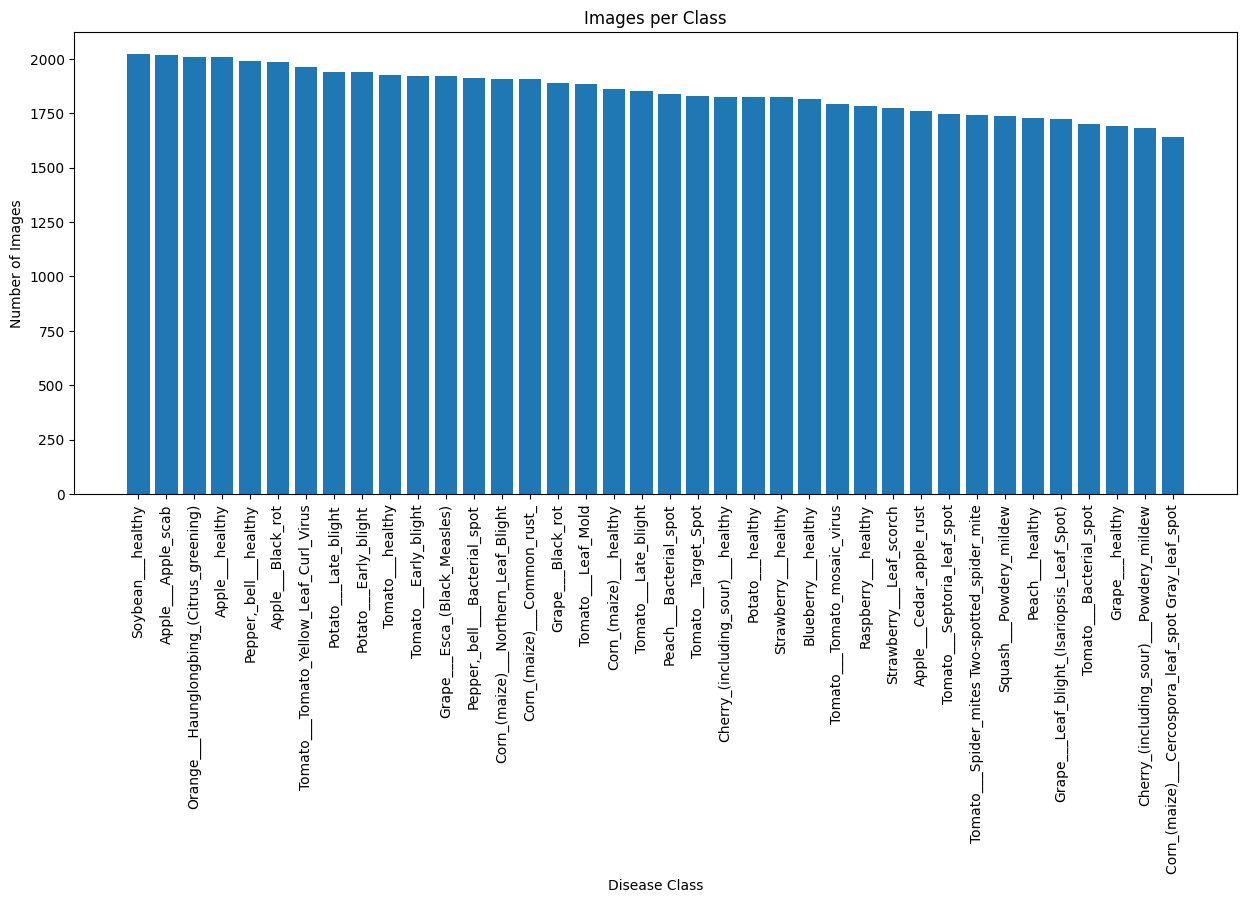

In [5]:

#  VISUALIZE CLASS DISTRIBUTION


df = df.sort_values("Images", ascending=False)

plt.figure(figsize=(15,6))

plt.bar(df["Class"], df["Images"])

plt.xticks(rotation=90)

plt.xlabel("Disease Class")

plt.ylabel("Number of Images")

plt.title("Images per Class")

plt.show()


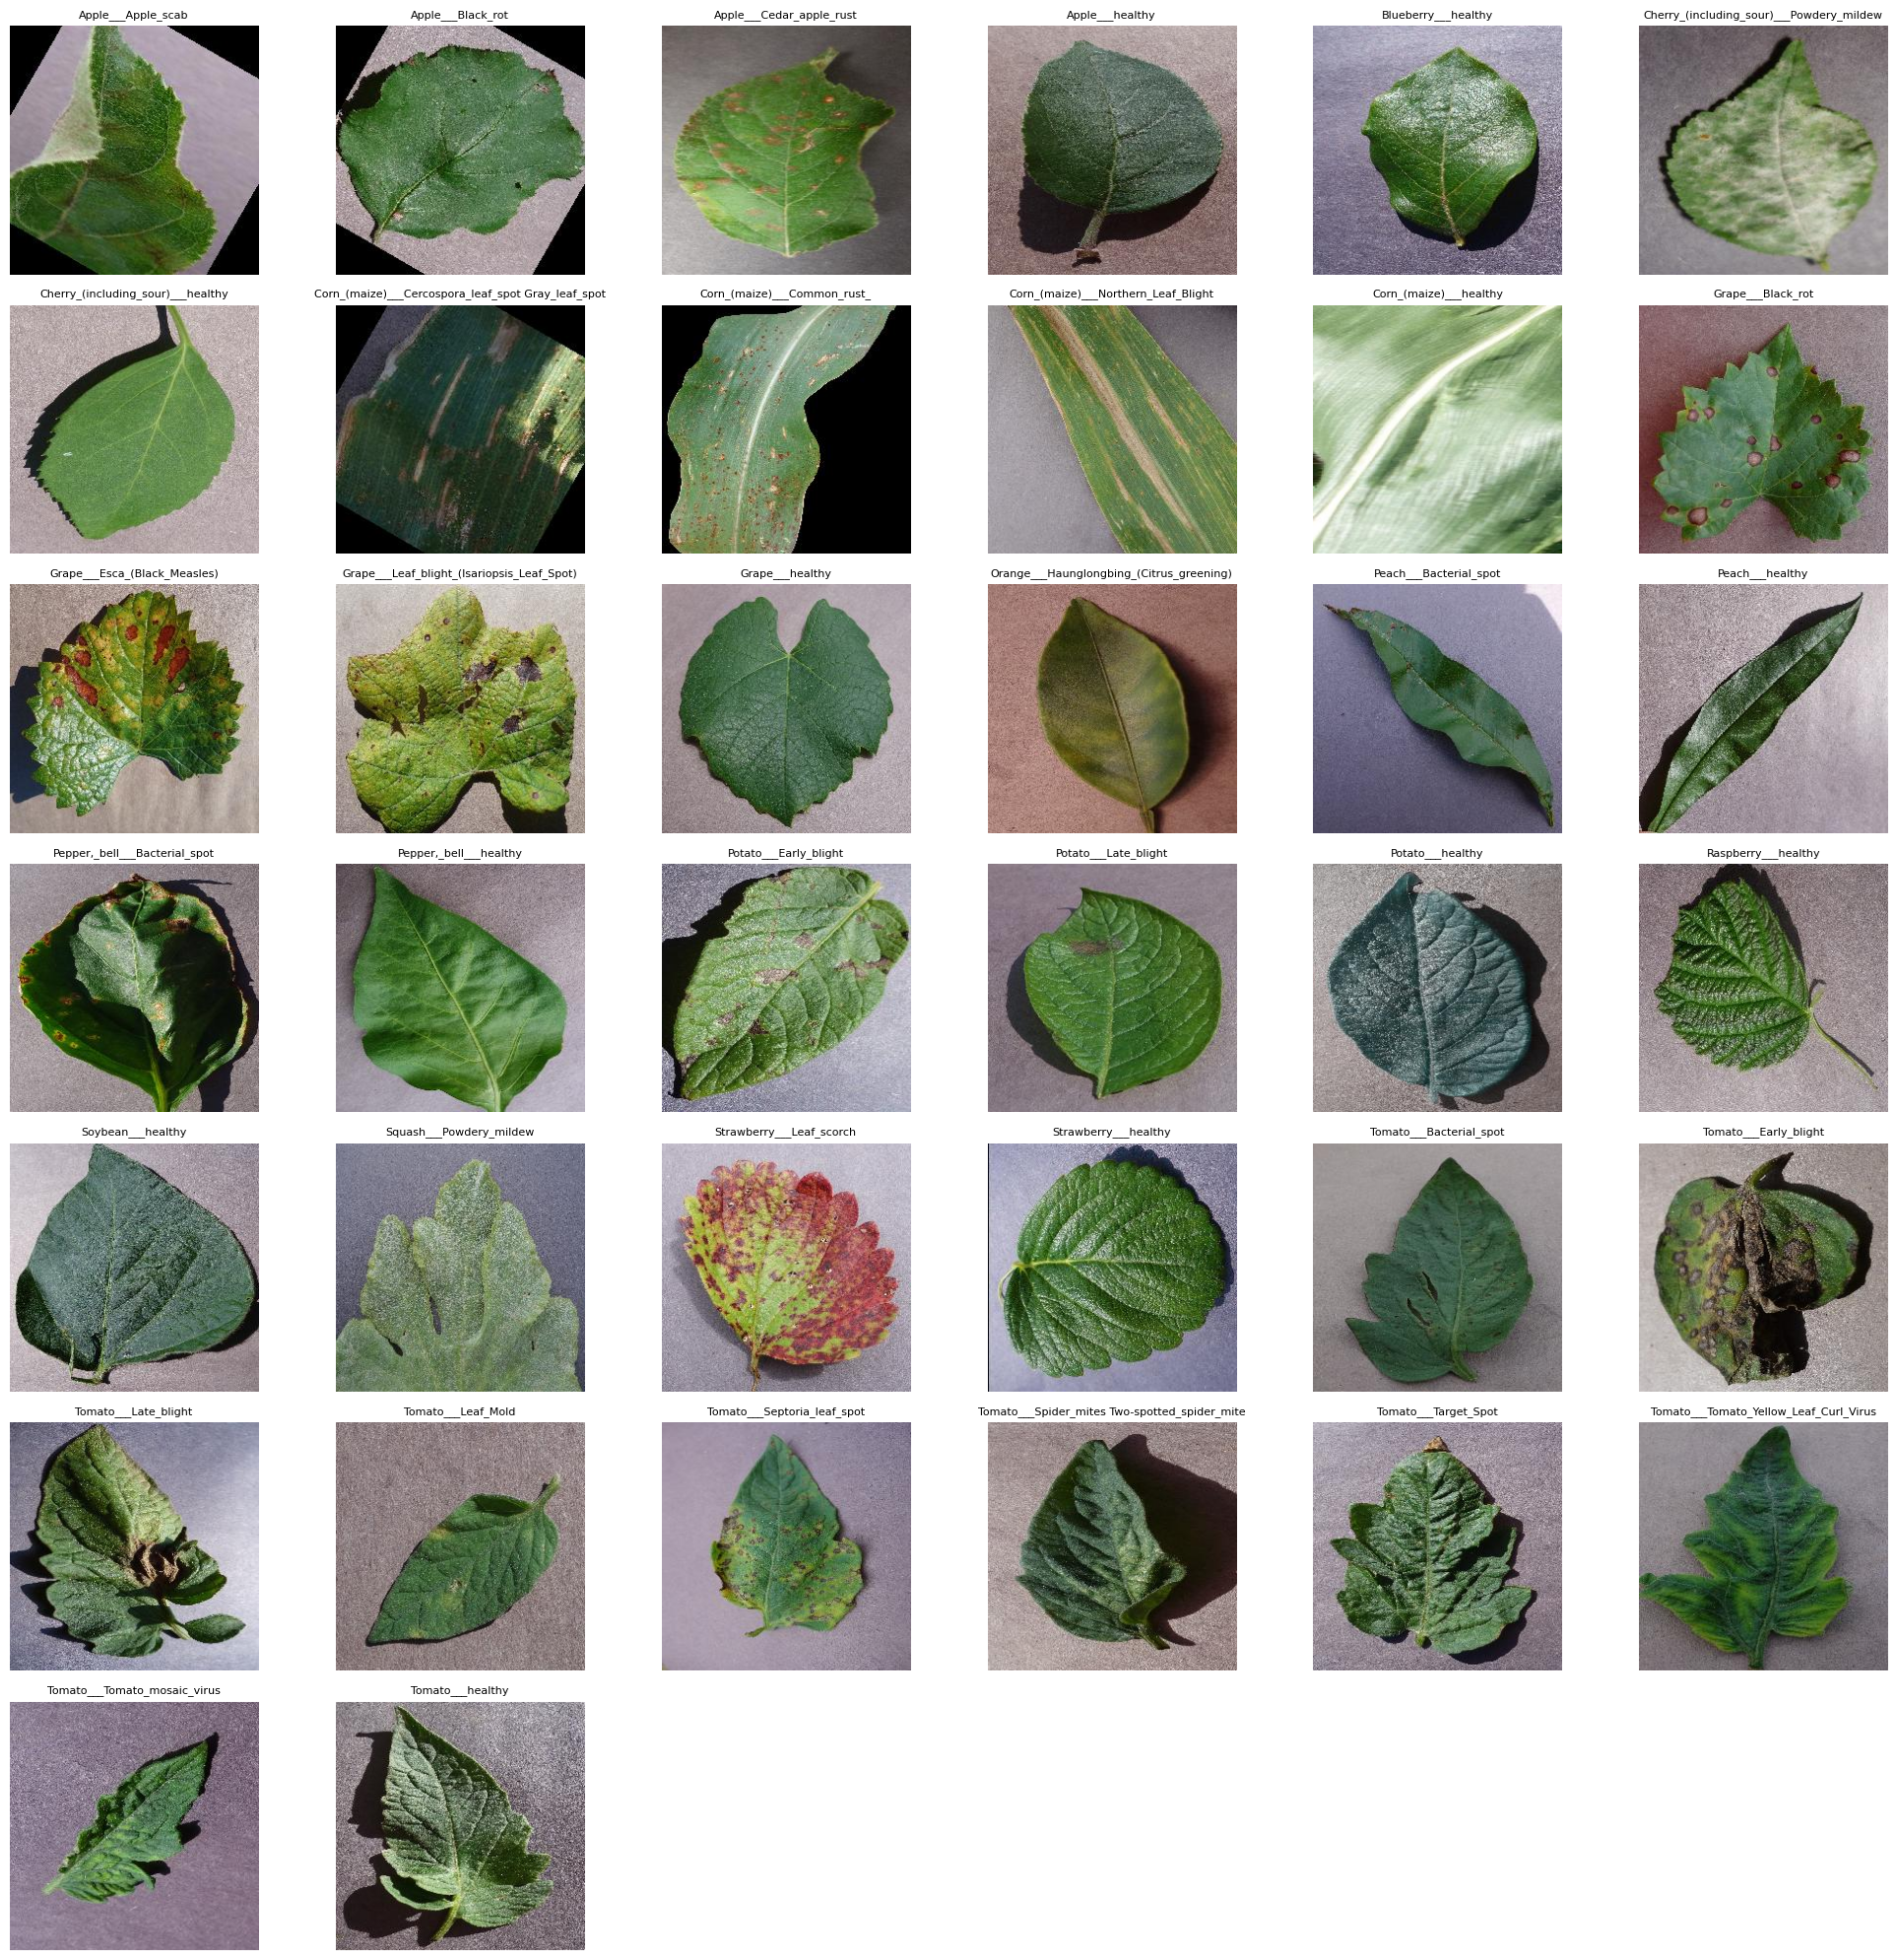

In [6]:

# DISPLAY FIRST IMAGE OF EACH CLASS


import cv2

plt.figure(figsize=(20,20))

for i, cls in enumerate(classes):

    img_path = os.path.join(TRAIN_DIR, cls, os.listdir(os.path.join(TRAIN_DIR, cls))[0])

    img = cv2.imread(img_path)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(7,6,i+1)

    plt.imshow(img)

    plt.title(cls, fontsize=8)

    plt.axis("off")

plt.tight_layout()

plt.show()

In [ ]:
#image shape 

sample_class = classes[0]

sample_image = os.path.join(TRAIN_DIR,
                            sample_class,
                            os.listdir(os.path.join(TRAIN_DIR,sample_class))[0])

img = cv2.imread(sample_image)

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print(img.shape)

In [8]:

# PIXEL VALUE RANGE


print("Minimum Pixel :", img.min())

print("Maximum Pixel :", img.max())

Minimum Pixel : 0
Maximum Pixel : 232


In [ ]:

# ENSORFLOW DATASET

IMG_SIZE = (224,224)

BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 70295 files belonging to 38 classes.


I0000 00:00:1783833957.075812      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1783833957.078719      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 17572 files belonging to 38 classes.


In [ ]:

#  CLASS NAMES


class_names = train_ds.class_names

print(class_names)

['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Sp

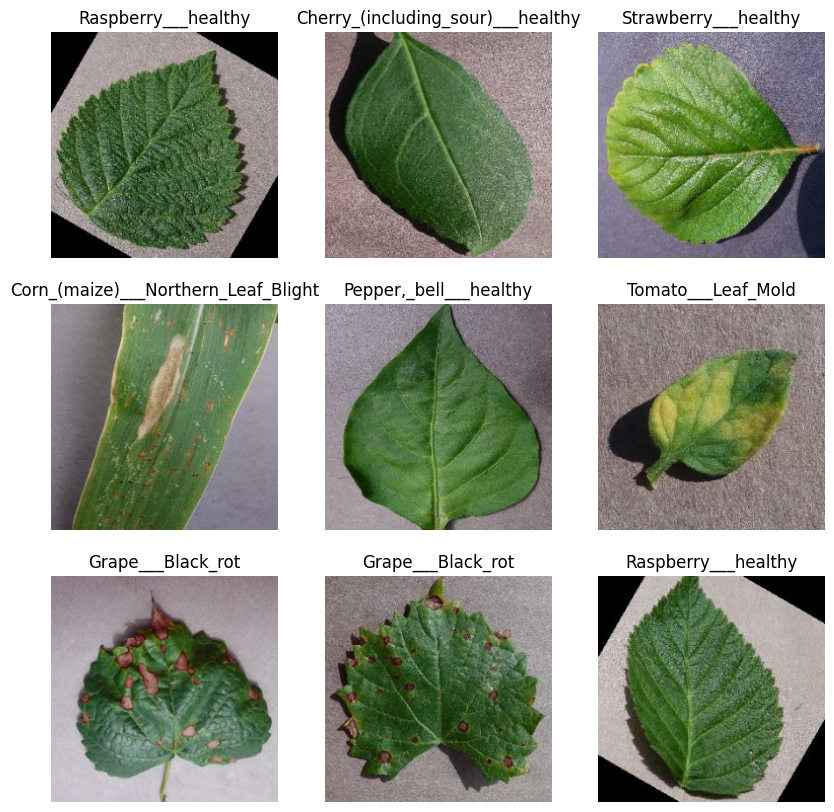

In [ ]:

# VISUALIZE A BATCH

plt.figure(figsize=(10,10))

for images, labels in train_ds.take(1):

    for i in range(9):

        plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

plt.show()